# Model Building — Malware Detection

Nesta fase são construídos, avaliados e comparados três modelos de classificação supervisionada:

- Decision Tree
- Random Forest
- XGBoost

O objetivo é identificar o modelo com melhor capacidade de deteção de malware, dando especial importância ao Recall, uma vez que um falso negativo corresponde a malware classificado como benigno.

O processo inclui:

- divisão dos dados em treino, validação e teste;
- treino dos modelos baseline;
- avaliação no conjunto de validação;
- cross-validation;
- seleção do melhor modelo;
- hyperparameter tuning;
- comparação entre baseline e versão otimizada;
- avaliação final no conjunto de teste;
- ROC-AUC;
- análise de overfitting.

In [14]:
# Preparar Ambiente

import sys
import subprocess
from pathlib import Path

em_colab = "google.colab" in sys.modules

if em_colab:
    pasta_projeto = Path("/content/IAAC-Projeto")

    if not pasta_projeto.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "https://github.com/diogocarvalho2025056-crypto/IAAC-Projeto.git"
            ],
            check=True
        )
else:
    pasta_projeto = Path.cwd().parent

if str(pasta_projeto) not in sys.path:
    sys.path.insert(0, str(pasta_projeto))

print("Pasta do projeto:")
print(pasta_projeto)

Pasta do projeto:
c:\Users\ze_ma\Documents\CTESP Cibersegurança\2.º Ano\Inteligência Artificial Aplicada à Cibersegurança\IAAC-Projeto


In [15]:
# Instalar Dependências

%pip install -q kagglehub[pandas-datasets]
%pip install -q xgboost
%pip install -q matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\ze_ma\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\ze_ma\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\ze_ma\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [16]:
## IMPORTS

import sys
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from pathlib import Path
from kagglehub import KaggleDatasetAdapter

C:\Users\ze_ma\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [17]:
from src.data_preparation_utils import (
    remover_colunas,
    remover_duplicados,
    separar_features_target,
    dividir_treino_validacao_teste
)

In [18]:
## Importar funções do model_utils

from src.model_utils import (
    criar_decision_tree,
    criar_random_forest,
    criar_xgboost,
    treinar_modelo,
    prever,
    avaliar_modelo,
    comparar_modelos,
    comparar_treino_validacao,
    importancia_features,
    avaliar_cross_validation,
    selecionar_melhor_modelo,
    obter_modelo_selecionado,
    otimizar_xgboost,
    selecionar_baseline_ou_otimizado,
    calcular_roc_auc,
    analisar_overfitting
)

## Importação do dataset

O dataset é importado diretamente da plataforma Kaggle.

É utilizado o ficheiro combinado `Malware_and_benign_recognition.csv`, contendo exemplos de ficheiros benignos e maliciosos.

In [19]:
# Importar do Kaggle

file_path = "Malware_and_benign_recognition.csv"

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "aashishzzz/malware-detection-dataset-with-new-malware-info",
    file_path
)

print("Dataset importado com sucesso.")
print("Dimensão original:", df.shape)

C:\Users\ze_ma\AppData\Local\Temp\ipykernel_31004\1153072359.py:5: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


100%|██████████| 251k/251k [00:00<00:00, 564kB/s]

Dataset importado com sucesso.
Dimensão original: (1156, 27)


## Preparação dos dados

São aplicadas as mesmas decisões definidas na fase de Data Preparation, de forma a garantir que o processo de modelação é reprodutível.

São removidas as seguintes colunas:

- `File`;
- `SuspiciousSectionNames`;
- `SectionCount`.

São também removidos os duplicados completos identificados após esta limpeza.


In [20]:
# Preparação dos dados

df_model = df.copy()

colunas_remover = [
    "File",
    "SuspiciousSectionNames",
    "SectionCount"
]

df_model = remover_colunas(
    df_model,
    colunas_remover
)

df_model = remover_duplicados(
    df_model
)

print("Dimensão após preparação:")
print(df_model.shape)

Dimensão após preparação:
(1148, 24)


In [21]:
# Features e Target

X, y = separar_features_target(
    df_model,
    "Malicious"
)

print("Features:", X.shape)
print("Target:", y.shape)

Features: (1148, 23)
Target: (1148,)


## Divisão em treino, validação e teste

Os dados são divididos da seguinte forma:

- 70% para treino;
- 15% para validação;
- 15% para teste.

É utilizado `stratify` para manter aproximadamente a mesma proporção entre ficheiros benignos e maliciosos nos três conjuntos.

O conjunto de teste fica reservado para a avaliação final.

In [22]:
# Treino, validação e teste - Split 70/15/15

(
    X_train,
    X_val,
    X_test,
    y_train,
    y_val,
    y_test
) = dividir_treino_validacao_teste(
    X,
    y
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

X_train: (803, 23)
X_val: (172, 23)
X_test: (173, 23)
y_train: (803,)
y_val: (172,)
y_test: (173,)


## Modelos utilizados

Foram selecionados três modelos supervisionados de classificação.

### Decision Tree
Utiliza uma estrutura de decisões hierárquicas para separar as classes.

### Random Forest
Combina várias árvores de decisão através de uma abordagem de ensemble baseada em bagging.

### XGBoost
Utiliza boosting, construindo árvores sequencialmente com o objetivo de corrigir erros cometidos pelas anteriores.

Nesta primeira análise são utilizadas configurações iniciais dos modelos, mantendo `random_state=42` para garantir reprodutibilidade. Não é ainda realizada otimização sistemática de hiperparâmetros.

In [23]:
# Criar Modelos

decision_tree = criar_decision_tree()

random_forest = criar_random_forest()

xgboost = criar_xgboost()

In [24]:
# Treinar modelos

decision_tree = treinar_modelo(
    decision_tree,
    X_train,
    y_train
)

random_forest = treinar_modelo(
    random_forest,
    X_train,
    y_train
)

xgboost = treinar_modelo(
    xgboost,
    X_train,
    y_train
)

print("Modelos treinados com sucesso.")

Modelos treinados com sucesso.


In [25]:
# Fazer previsões na validação

y_pred_val_dt = prever(
    decision_tree,
    X_val
)

y_pred_val_rf = prever(
    random_forest,
    X_val
)

y_pred_val_xgb = prever(
    xgboost,
    X_val
)

## Avaliação dos modelos

Os modelos são avaliados através das seguintes métricas:

- Accuracy;
- Precision;
- Recall;
- F1-score;
- matriz de confusão;
- relatório de classificação.

No contexto deste projeto, o Recall da classe malware é particularmente relevante, porque um falso negativo corresponde a um ficheiro malicioso classificado como benigno.

In [26]:
## Avaliar os modelos

resultado_dt, matriz_dt, relatorio_dt = avaliar_modelo(
    "Decision Tree",
    y_val,
    y_pred_val_dt,
    ["Benigno", "Malware"]
)

resultado_rf, matriz_rf, relatorio_rf = avaliar_modelo(
    "Random Forest",
    y_val,
    y_pred_val_rf,
    ["Benigno", "Malware"]
)

resultado_xgb, matriz_xgb, relatorio_xgb = avaliar_modelo(
    "XGBoost",
    y_val,
    y_pred_val_xgb,
    ["Benigno", "Malware"]
)

In [27]:
# Comparação Geral

resultados_validacao = [
    resultado_dt,
    resultado_rf,
    resultado_xgb
]

tabela_validacao = comparar_modelos(
    resultados_validacao
)

display(tabela_validacao)

,Modelo,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.982558,0.976744,0.988235,0.982456
1,Random Forest,0.982558,0.976744,0.988235,0.982456
2,XGBoost,0.982558,0.976744,0.988235,0.982456


### Interpretação

Os três modelos apresentaram exatamente o mesmo desempenho no conjunto de validação.

Todos atingiram aproximadamente:

- Accuracy: 98,26%
- Precision: 97,67%
- Recall: 98,82%
- F1-score: 98,25%

Como os resultados são idênticos, esta avaliação não é suficiente para selecionar um único modelo.

In [28]:
# Treino VS Validação

comparacao_tv = []

for nome, modelo in [
    ("Decision Tree", decision_tree),
    ("Random Forest", random_forest),
    ("XGBoost", xgboost)
]:

    treino, validacao = comparar_treino_validacao(
        modelo,
        X_train,
        y_train,
        X_val,
        y_val
    )

    comparacao_tv.append({
        "Modelo": nome,
        "Accuracy treino": treino,
        "Accuracy validação": validacao
    })

display(
    pd.DataFrame(comparacao_tv)
)

,Modelo,Accuracy treino,Accuracy validação
0,Decision Tree,1.0,0.982558
1,Random Forest,1.0,0.982558
2,XGBoost,1.0,0.982558


### Treino vs Validação

Os três modelos obtiveram 100% de Accuracy no conjunto de treino e aproximadamente 98,26% na validação.

Existe uma pequena diferença entre treino e validação, pelo que é importante complementar esta análise com cross-validation.

## Análise da importância das features

Os três modelos utilizados permitem estimar a importância relativa das características utilizadas na classificação.

Esta análise ajuda a perceber quais as variáveis que mais contribuíram para as decisões dos modelos.

Os valores de importância devem, no entanto, ser interpretados com cautela, uma vez que representam a utilização das variáveis pelo modelo e não uma relação causal com a presença de malware.

In [29]:
# Feature importance - Decision Tree

importancias_dt = importancia_features(
    decision_tree,
    X.columns
)

display(importancias_dt.head(10))

,Feature,Importancia
6,ImageBase,0.774524
10,SizeOfHeaders,0.174423
11,Characteristics,0.016413
22,OverlaySize,0.010083
16,TextSectionSize,0.009965
15,MinSectionEntropy,0.004970
13,AvgSectionEntropy,0.004902
3,AddressOfEntryPoint,0.003737
1,SizeOfInitializedData,0.000982
0,SizeOfCode,0.000000


In [30]:
# Feature importance - Random Forest

importancias_rf = importancia_features(
    random_forest,
    X.columns
)

display(importancias_rf.head(10))

,Feature,Importancia
6,ImageBase,0.190628
5,BaseOfData,0.187340
10,SizeOfHeaders,0.156077
11,Characteristics,0.064755
8,DllCharacteristics,0.052526
18,ImportedDLLs,0.051129
14,MaxSectionEntropy,0.044407
7,NumberOfSections,0.038385
19,ImportedFunctions,0.035879
9,SizeOfImage,0.034527


In [31]:
# Feature importance - XGBoost

importancias_xgb = importancia_features(
    xgboost,
    X.columns
)

display(importancias_xgb.head(10))

,Feature,Importancia
6,ImageBase,0.642255
10,SizeOfHeaders,0.207252
11,Characteristics,0.034866
21,ExportedFunctions,0.022281
22,OverlaySize,0.014910
14,MaxSectionEntropy,0.012323
18,ImportedDLLs,0.009854
9,SizeOfImage,0.009754
15,MinSectionEntropy,0.008501
5,BaseOfData,0.007847


## Importância das features

A análise das feature importances mostra que algumas variáveis já identificadas durante o Data Understanding voltam a surgir com peso significativo nos modelos.

Entre as características mais relevantes encontram-se:

- `ImageBase`;
- `SizeOfHeaders`;
- `BaseOfData`;
- `DllCharacteristics`;
- `Characteristics`.

A distribuição da importância não é igual entre os modelos.

A Decision Tree concentra grande parte da decisão em poucas características, enquanto a Random Forest distribui a importância por um conjunto mais alargado de variáveis.

Estas importâncias representam a forma como os modelos utilizam as características para realizar as previsões e não devem ser interpretadas como relações causais.

## Cross-validation

Foi utilizada validação cruzada estratificada com 5 folds exclusivamente sobre o conjunto de treino.

O Recall e o F1-score são utilizados como principais métricas de comparação.

O Recall tem particular importância porque um falso negativo representa malware não detetado.

In [32]:
## Cross Validation

resultado_cv_dt, recall_dt, f1_dt = avaliar_cross_validation(
    "Decision Tree",
    decision_tree,
    X_train,
    y_train
)

resultado_cv_rf, recall_rf, f1_rf = avaliar_cross_validation(
    "Random Forest",
    random_forest,
    X_train,
    y_train
)

resultado_cv_xgb, recall_xgb, f1_xgb = avaliar_cross_validation(
    "XGBoost",
    xgboost,
    X_train,
    y_train
)

resultados_cv = [
    resultado_cv_dt,
    resultado_cv_rf,
    resultado_cv_xgb
]

display(
    pd.DataFrame(resultados_cv)
)


,Modelo,Recall CV,F1 CV,Desvio Recall,Desvio F1
0,Decision Tree,0.989873,0.989873,0.009473,0.006471
1,Random Forest,0.997468,0.991226,0.005063,0.004930
2,XGBoost,0.997468,0.993742,0.005063,0.006804


### Resultados da cross-validation

Os resultados médios obtidos foram aproximadamente:

- Decision Tree:
  - Recall: 98,99%
  - F1-score: 98,99%

- Random Forest:
  - Recall: 99,75%
  - F1-score: 99,12%

- XGBoost:
  - Recall: 99,75%
  - F1-score: 99,37%

Random Forest e XGBoost obtiveram o mesmo Recall médio.

O XGBoost apresentou o maior F1-score médio, sendo por isso selecionado para a fase seguinte.

## Seleção do melhor modelo

Os três modelos apresentaram resultados idênticos no conjunto de validação.

Na cross-validation, Random Forest e XGBoost apresentaram o mesmo Recall médio, aproximadamente 99,75%.

O XGBoost apresentou, contudo, o F1-score médio mais elevado, aproximadamente 99,37%.

Por este motivo, o XGBoost foi selecionado para a fase seguinte de otimização e avaliação.

In [33]:
## Selecionar melhor modelo

nome_melhor_modelo = selecionar_melhor_modelo(
    resultados_validacao,
    resultados_cv
)

print(
    "Modelo selecionado:",
    nome_melhor_modelo
)

melhor_modelo = obter_modelo_selecionado(
    nome_melhor_modelo,
    decision_tree,
    random_forest,
    xgboost
)

Modelo selecionado: XGBoost


## Hyperparameter Tuning

Depois de selecionado o XGBoost, é realizada otimização de hiperparâmetros utilizando `GridSearchCV`.

A pesquisa utiliza 5-fold stratified cross-validation e otimiza o Recall.

Foram analisados:

- `n_estimators`;
- `max_depth`;
- `learning_rate`;
- `reg_alpha`;
- `reg_lambda`.

In [34]:
## GridSearchCV

grid_search = otimizar_xgboost(
    X_train,
    y_train
)

print(
    "Melhores parâmetros:"
)

print(
    grid_search.best_params_
)

print(
    "\nMelhor Recall médio CV:"
)

print(
    grid_search.best_score_
)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Melhores parâmetros:
{'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100, 'reg_alpha': 0, 'reg_lambda': 1}

Melhor Recall médio CV:
0.9974683544303797


In [35]:
## Modelo Otimizado

xgboost_otimizado = (
    grid_search.best_estimator_
)

y_pred_val_xgb_otimizado = prever(
    xgboost_otimizado,
    X_val
)

(
    resultado_xgb_otimizado,
    matriz_xgb_otimizado,
    relatorio_xgb_otimizado
) = avaliar_modelo(
    "XGBoost Otimizado",
    y_val,
    y_pred_val_xgb_otimizado,
    ["Benigno", "Malware"]
)

In [36]:
## Comparar baseline com otimizado

comparacao_xgb = pd.DataFrame([
    resultado_xgb,
    resultado_xgb_otimizado
])

display(
    comparacao_xgb
)

,Modelo,Accuracy,Precision,Recall,F1-score
0,XGBoost,0.982558,0.976744,0.988235,0.982456
1,XGBoost Otimizado,0.982558,0.976744,0.988235,0.982456


### Baseline vs modelo otimizado

O XGBoost otimizado apresentou exatamente os mesmos resultados do XGBoost baseline no conjunto de validação:

- Accuracy: 98,26%
- Precision: 97,67%
- Recall: 98,82%
- F1-score: 98,25%

Assim, o processo de tuning não produziu uma melhoria das métricas de validação.

Apesar de o modelo otimizado apresentar menor diferença entre treino e validação, não existe ganho de desempenho que justifique substituir o baseline.

In [37]:
## Escolher baseline ou otimizado

modelo_final, nome_modelo_final = selecionar_baseline_ou_otimizado(
    resultado_xgb,
    resultado_xgb_otimizado,
    xgboost,
    xgboost_otimizado
)

print(
    "Modelo final:",
    nome_modelo_final
)

Modelo final: XGBoost Baseline


## Avaliação final no conjunto de teste

O conjunto de teste é agora utilizado para avaliar o modelo final.

Este conjunto não foi utilizado no treino, na comparação dos modelos baseline nem no hyperparameter tuning.

In [38]:
## Teste Final

y_pred_test = prever(
    modelo_final,
    X_test
)

(
    resultado_final,
    matriz_final,
    relatorio_final
) = avaliar_modelo(
    nome_modelo_final + " - Teste Final",
    y_test,
    y_pred_test,
    ["Benigno", "Malware"]
)

display(
    pd.DataFrame([
        resultado_final
    ])
)

print(
    "Matriz de confusão:"
)

print(
    matriz_final
)

print(
    relatorio_final
)

,Modelo,Accuracy,Precision,Recall,F1-score
0,XGBoost Baseline - Teste Final,0.976879,0.955056,1.0,0.977011


Matriz de confusão:
[[84  4]
 [ 0 85]]
              precision    recall  f1-score   support

     Benigno       1.00      0.95      0.98        88
     Malware       0.96      1.00      0.98        85

    accuracy                           0.98       173
   macro avg       0.98      0.98      0.98       173
weighted avg       0.98      0.98      0.98       173



### Resultados finais

O XGBoost Baseline apresentou no conjunto de teste:

- Accuracy: 97,69%
- Precision: 95,51%
- Recall: 100%
- F1-score: 97,70%

A matriz de confusão foi:

- True Negatives: 84
- False Positives: 4
- False Negatives: 0
- True Positives: 85

Assim, todos os 85 ficheiros maliciosos presentes no conjunto de teste foram corretamente identificados.

ROC-AUC: 0.9981283422459893


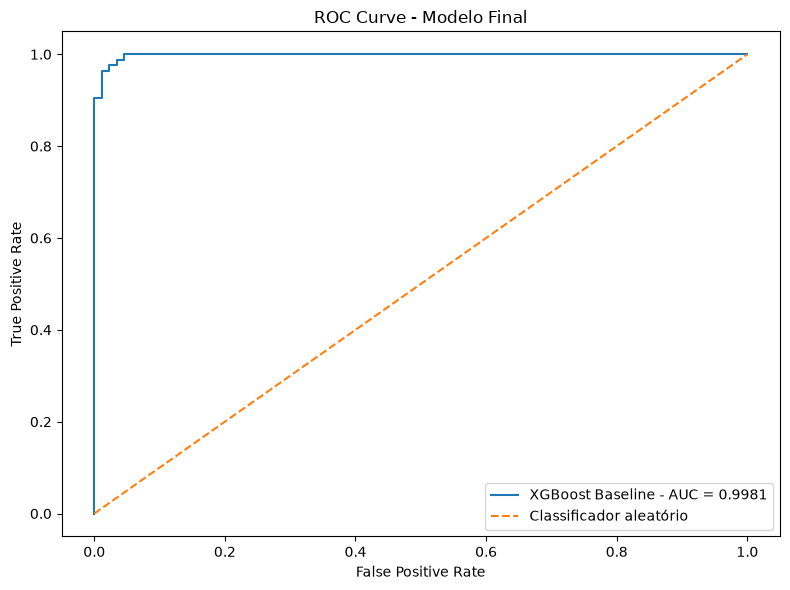

In [39]:
## ROC / AUC

auc, fpr, tpr, thresholds = calcular_roc_auc(
    modelo_final,
    X_test,
    y_test
)

print(
    "ROC-AUC:",
    auc
)

plt.figure(
    figsize=(8, 6)
)

plt.plot(
    fpr,
    tpr,
    label=f"{nome_modelo_final} - AUC = {auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Classificador aleatório"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC Curve - Modelo Final"
)

plt.legend()

plt.tight_layout()

plt.show()

### ROC-AUC

O modelo final apresentou um ROC-AUC de aproximadamente 0,9981.

Este resultado indica uma capacidade muito elevada de discriminar entre ficheiros benignos e maliciosos ao longo de diferentes thresholds de classificação.

Apesar do valor elevado, este resultado deve ser interpretado no contexto do dataset utilizado e não como garantia de desempenho idêntico em dados externos.

In [40]:
## Overfitting

overfitting_dt = analisar_overfitting(
    "Decision Tree",
    decision_tree,
    X_train,
    y_train,
    X_val,
    y_val
)

overfitting_rf = analisar_overfitting(
    "Random Forest",
    random_forest,
    X_train,
    y_train,
    X_val,
    y_val
)

overfitting_xgb = analisar_overfitting(
    "XGBoost Baseline",
    xgboost,
    X_train,
    y_train,
    X_val,
    y_val
)

overfitting_xgb_otimizado = analisar_overfitting(
    "XGBoost Otimizado",
    xgboost_otimizado,
    X_train,
    y_train,
    X_val,
    y_val
)

comparacao_overfitting = pd.DataFrame([
    overfitting_dt,
    overfitting_rf,
    overfitting_xgb,
    overfitting_xgb_otimizado
])

display(
    comparacao_overfitting
)

,Modelo,Accuracy treino,Accuracy validação,Diferença
0,Decision Tree,1.000000,0.982558,0.017442
1,Random Forest,1.000000,0.982558,0.017442
2,XGBoost Baseline,1.000000,0.982558,0.017442
3,XGBoost Otimizado,0.992528,0.982558,0.009970


## Overfitting e Bias-Variance

Decision Tree, Random Forest e XGBoost Baseline apresentaram 100% de Accuracy no conjunto de treino e aproximadamente 98,26% no conjunto de validação.

A diferença entre treino e validação foi de cerca de 1,74 pontos percentuais nos três modelos baseline.

O XGBoost otimizado apresentou aproximadamente 99,25% de Accuracy no treino e 98,26% na validação, reduzindo essa diferença para cerca de 1,00 ponto percentual.

Esta redução sugere menor ajuste específico aos dados de treino. No entanto, como o desempenho no conjunto de validação não melhorou, a otimização não trouxe vantagem suficiente para justificar a substituição do XGBoost Baseline.

Os resultados não evidenciam underfitting e também não sugerem overfitting severo, uma vez que o desempenho de validação se mantém muito elevado e consistente com os resultados obtidos em cross-validation.

## Conclusão

Foram avaliados três modelos de classificação: Decision Tree, Random Forest e XGBoost.

Os três apresentaram resultados idênticos no conjunto de validação.

A cross-validation permitiu distinguir melhor os modelos, tendo o XGBoost apresentado Recall médio de aproximadamente 99,75% e o maior F1-score médio, aproximadamente 99,37%.

O XGBoost foi posteriormente submetido a hyperparameter tuning através de GridSearchCV.

A configuração otimizada apresentou os mesmos resultados do baseline na validação, pelo que o XGBoost Baseline foi mantido como modelo final.

No conjunto de teste, o modelo atingiu aproximadamente 97,69% de Accuracy, 95,51% de Precision, 100% de Recall e 97,70% de F1-score.

O ROC-AUC foi aproximadamente 0,9981.

A ausência de falsos negativos no conjunto de teste é particularmente relevante neste contexto, uma vez que significa que todos os ficheiros maliciosos presentes no conjunto foram detetados.

Estes resultados são muito elevados, mas devem ser interpretados considerando as características e dimensão do dataset utilizado.